In [3]:
import time
from typing import Optional

class AVLNode:
    def __init__(self, key):
        self.key = key
        self.left = None
        self.right = None
        self.height = 1



class AVLTree:
    def __init__(self):
        self.insert_calls = 0      # счётчик рекурсивных вызовов insert
        self.delete_calls = 0      # счётчик рекурсивных вызовов delete
        self.rotate_left_count = 0  # количество левых поворотов
        self.rotate_right_count = 0 # количество правых поворотов
        self.total_operations = 0   # общее число операций (вставка + удаление)


    def _height(self, node: Optional[AVLNode]) -> int:
        return node.height if node else 0

    def _balance_factor(self, node: Optional[AVLNode]) -> int:
        if not node:
            return 0
        return self._height(node.left) - self._height(node.right)

    def _update_height(self, node: Optional[AVLNode]):
        if node:
            node.height = max(self._height(node.left), self._height(node.right)) + 1

    def _rotate_left(self, x: AVLNode) -> AVLNode:
        self.rotate_left_count += 1
        y = x.right
        T2 = y.left

        y.left = x
        x.right = T2

        self._update_height(x)
        self._update_height(y)
        return y

    def _rotate_right(self, y: AVLNode) -> AVLNode:
        self.rotate_right_count += 1
        x = y.left
        T2 = x.right

        x.right = y
        y.left = T2

        self._update_height(y)
        self._update_height(x)
        return x

    def insert(self, root: Optional[AVLNode], key: int) -> AVLNode:
        self.insert_calls += 1
        self.total_operations += 1

        if not root:
            return AVLNode(key)

        if key < root.key:
            root.left = self.insert(root.left, key)
        elif key > root.key:
            root.right = self.insert(root.right, key)
        else:
            return root  # дубликаты не вставляем

        self._update_height(root)
        balance = self._balance_factor(root)

        # Левый левый
        if balance > 1 and key < root.left.key:
            return self._rotate_right(root)
        # Правый правый
        if balance < -1 and key > root.right.key:
            return self._rotate_left(root)
        # Левый правый
        if balance > 1 and key > root.left.key:
            root.left = self._rotate_left(root.left)
            return self._rotate_right(root)
        # Правый левый
        if balance < -1 and key < root.right.key:
            root.right = self._rotate_right(root.right)
            return self._rotate_left(root)


        return root

    def delete(self, root: Optional[AVLNode], key: int) -> Optional[AVLNode]:
        self.delete_calls += 1
        self.total_operations += 1

        if not root:
            return root

        if key < root.key:
            root.left = self.delete(root.left, key)
        elif key > root.key:
            root.right = self.delete(root.right, key)
        else:
            if not root.left:
                return root.right
            elif not root.right:
                return root.left
            else:
                successor = self._find_min(root.right)
                root.key = successor.key
                root.right = self.delete(root.right, successor.key)

        if not root:
            return root

        self._update_height(root)
        balance = self._balance_factor(root)

        # Левый левый
        if balance > 1 and self._balance_factor(root.left) >= 0:
            return self._rotate_right(root)
        # Левый правый
        if balance > 1 and self._balance_factor(root.left) < 0:
            root.left = self._rotate_left(root.left)
            return self._rotate_right(root)
        # Правый правый
        if balance < -1 and self._balance_factor(root.right) <= 0:
            return self._rotate_left(root)
        # Правый левый
        if balance < -1 and self._balance_factor(root.right) > 0:
            root.right = self._rotate_right(root.right)
            return self._rotate_left(root)

        return root

    def _find_min(self, node: AVLNode) -> AVLNode:
        while node.left:
            node = node.left
        return node

    def print_tree(self, root: Optional[AVLNode], level=0, prefix="Root: "):
        if root:
            print(" " * (level * 4) + prefix + str(root.key))
            if root.left or root.right:
                if root.left:
                    self.print_tree(root.left, level + 1, "L--- ")
                else:
                    print(" " * ((level + 1) * 4) + "L--- None")
                if root.right:
                    self.print_tree(root.right, level + 1, "R--- ")
                else:
                    print(" " * ((level + 1) * 4) + "R--- None")

    def get_stats(self) -> dict:
        """Возвращает статистику по операциям"""
        return {
            "total_operations": self.total_operations,
            "insert_calls": self.insert_calls,
            "delete_calls": self.delete_calls,
            "rotate_left": self.rotate_left_count,
            "rotate_right": self.rotate_right_count,
            "total_rotations": self.rotate_left_count + self.rotate_right_count
        }

    def reset_stats(self):
        """Обнуляет статистику для нового замера"""
        self.insert_calls = 0
        self.delete_calls = 0
        self.rotate_left_count = 0
        self.rotate_right_count = 0
        self.total_operations = 0


In [7]:
# Создаём дерево
avl = AVLTree()
root = None

# Вставляем ключи
keys = [20, 10, 30, 5, 40, 50, 25]
for key in keys:
    root = avl.insert(root, key)

print("Дерево после вставки:")
avl.print_tree(root)

#Удаляем ключ
root = avl.delete(root, 30)
print("\nДерево после удаления 30:")
avl.print_tree(root)


Дерево после вставки:
Root: 20
    L--- 10
        L--- 5
        R--- None
    R--- 40
        L--- 30
            L--- 25
            R--- None
        R--- 50

Дерево после удаления 30:
Root: 20
    L--- 10
        L--- 5
        R--- None
    R--- 40
        L--- 25
        R--- 50


In [30]:
def benchmark_avl_operations(tree: AVLTree, keys_insert: list, keys_delete: list):
    root = None
    tree.reset_stats()

    # Замер вставки
    start_time = time.perf_counter()
    for key in keys_insert:
        root = tree.insert(root, key)
    insert_time = time.perf_counter() - start_time

    # Замер удаления
    start_time = time.perf_counter()
    for key in keys_delete:
        root = tree.delete(root, key)
    delete_time = time.perf_counter() - start_time

    stats = tree.get_stats()
    return {
        "insert_time_sec": insert_time,
        "delete_time_sec": delete_time,
        "stats": stats
    }

def analyze_complexity():
    tree = AVLTree()

    # Тестовые наборы разного размера
    sizes = [100, 200, 500, 1000, 1500, 2000, 5000, 7000, 10000]
    results = []
    insert_res = []
    for n in sizes:
        keys_insert = list(range(n))  # 0, 1, 2, ..., n-1
        keys_delete = keys_insert[:n//2]  # удаляем половину


        result = benchmark_avl_operations(tree, keys_insert, keys_delete)
        print("-"*10 + str(n) + "-"*10)
        print(result)
        insert_res.append(result['insert_time_sec'])
    return insert_res

In [31]:
resulst = analyze_complexity()
resulst

----------100----------
{'insert_time_sec': 0.002024166999035515, 'delete_time_sec': 0.0008357909991900669, 'stats': {'total_operations': 936, 'insert_calls': 673, 'delete_calls': 263, 'rotate_left': 116, 'rotate_right': 0, 'total_rotations': 116}}
----------200----------
{'insert_time_sec': 0.004088708001290797, 'delete_time_sec': 0.00154633400052262, 'stats': {'total_operations': 2146, 'insert_calls': 1545, 'delete_calls': 601, 'rotate_left': 240, 'rotate_right': 0, 'total_rotations': 240}}
----------500----------
{'insert_time_sec': 0.013221958999565686, 'delete_time_sec': 0.002824375000272994, 'stats': {'total_operations': 6172, 'insert_calls': 4489, 'delete_calls': 1683, 'rotate_left': 614, 'rotate_right': 0, 'total_rotations': 614}}
----------1000----------
{'insert_time_sec': 0.009191749999445165, 'delete_time_sec': 0.002920208000432467, 'stats': {'total_operations': 13718, 'insert_calls': 9977, 'delete_calls': 3741, 'rotate_left': 1238, 'rotate_right': 0, 'total_rotations': 123

[0.002024166999035515,
 0.004088708001290797,
 0.013221958999565686,
 0.009191749999445165,
 0.014067083000554703,
 0.01938641700144217,
 0.05212391699933505,
 0.07452004200058582,
 0.10977675000140152]

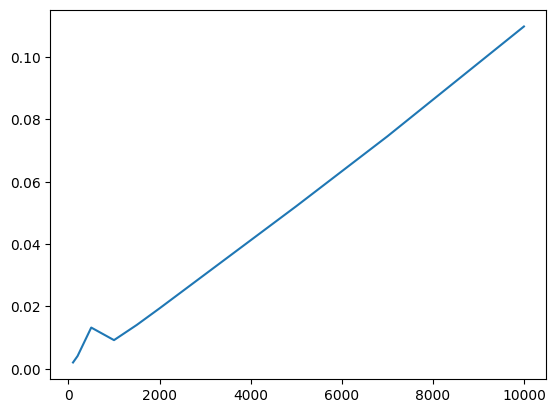

In [33]:
from matplotlib import pyplot as plt

plt.plot([100, 200, 500, 1000, 1500, 2000, 5000, 7000, 10000], resulst)

In [10]:
tree = AVLTree()
root = None
keys = list(range(10))
for key in keys:
    root = avl.insert(root, key)

tree.print_tree(root)

Root: 3
    L--- 1
        L--- 0
        R--- 2
    R--- 7
        L--- 5
            L--- 4
            R--- 6
        R--- 8
            L--- None
            R--- 9


In [35]:
tree = AVLTree()

# Тестовые наборы разного размера
sizes = [100, 200, 500, 1000, 1500, 2000, 5000, 7000, 10000]
results = []
insert_res = []
for n in sizes:
    tree = AVLTree()
    root = None
    keys_insert = list(range(n))  # 0, 1, 2, ..., n-1
    for key in keys_insert:
        root = tree.insert(root, key)
    stats = tree.get_stats()
    insert_res.append(stats['insert_calls'])

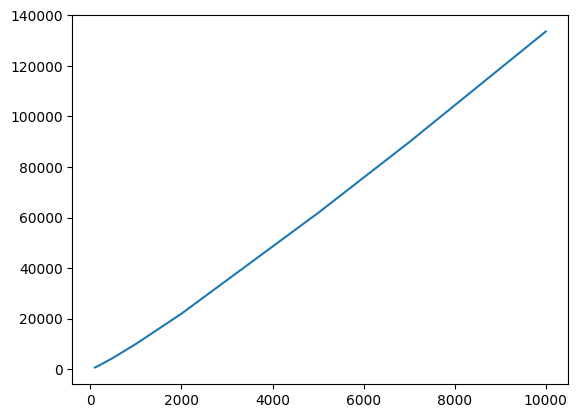

In [36]:
plt.plot([100, 200, 500, 1000, 1500, 2000, 5000, 7000, 10000], insert_res)

In [38]:
insert_res[0]

673